# Heisenberg Chain — Fourier TCI with Hybrid Oracle (Phase 5)

Reproduces **Figure 10** and **Table I** from the manuscript (Chapter VII.D).

## Hamiltonian
$$H(J_1,J_2,J_3,J_4)=\sum_{i=1}^{N-1}(J_1 X_iX_{i+1}+J_2 Y_iY_{i+1}+J_3 Z_iZ_{i+1})+J_4\sum_{i=1}^N Z_i$$

## How to run
* **Quick test** (`QUICK_MODE = true`): N=4, ~3 min, verifies the full pipeline.
* **Full mode** (`QUICK_MODE = false`): N=9–12, reproduces manuscript figures.

Edit the **Configuration** cell, then `Kernel → Restart & Run All`.

In [2]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  MASTER CONFIGURATION — edit here, everything adjusts automatically     ║
# ╚══════════════════════════════════════════════════════════════════════════╝

# ── Mode ─────────────────────────────────────────────────────────────────────
QUICK_MODE = false    # true → fast sanity check (N≤5, ~3 min total)
                     # false → manuscript-grade run (N=9–12, may take hours)

# ── Physics ───────────────────────────────────────────────────────────────────
N_SINGLE  = QUICK_MODE ? 4 : 9      # chain length for single-N experiment
N_STEPS   = QUICK_MODE ? 2 : 3      # Trotter steps K  (manuscript: K=3)
T_EVOLVE  = 1.0                     # total evolution time
J4_FIG    = -1.0                    # fixed J4 for 2-D heatmaps

# ── TCI hyperparameters ───────────────────────────────────────────────────────
CHI_MAX      = QUICK_MODE ? 6  : 24  # max bond dim (manuscript: χ=24)
α            = 2                     # oversampling: M^(k) = α d_k  (Thm 1; α=1 gives ill-conditioned V)
TCI_TOL      = 1e-8
MPS_MAXDIM   = 128
MPS_CUTOFF   = 1e-12
YAO_CUTOVER  = 17                    # N > this → MPS oracle

# ── Experiment lists ──────────────────────────────────────────────────────────
N_LIST    = QUICK_MODE ? [4]    : [9, 10, 11, 12, 13, 14, 15, 16]   # Table I
CHI_SCAN  = QUICK_MODE ? [3, 6] : [3, 6, 9, 12]     # Fig 10(b) panels
N_SCALE   = QUICK_MODE ? [4]    : [9, 10, 11, 12, 14, 16, 18, 20]

# ── Figure / validation ───────────────────────────────────────────────────────
GRID_SIZE = QUICK_MODE ? 20  : 200
M_VAL     = QUICK_MODE ? 50  : 500
N_SEEDS   = QUICK_MODE ? 2   : 5
RNG_SEED  = 42

# ── Output directories ────────────────────────────────────────────────────────
DIR_RAW       = "results/raw"
DIR_PROCESSED = "results/processed"
DIR_FIGURES   = "figures"
DIR_LOGS      = "logs"

dt_single = T_EVOLVE / N_STEPS

@info "Mode: $(QUICK_MODE ? "QUICK (N≤5, fast)" : "FULL (manuscript-grade)")"
@info "N=$N_SINGLE  K=$N_STEPS  chi_max=$CHI_MAX  grid=$(GRID_SIZE)x$(GRID_SIZE)"


[ Info: Mode: FULL (manuscript-grade)
[ Info: N=9  K=3  chi_max=24  grid=200x200


## 1. Setup

In [3]:
using Pkg
Pkg.activate(".")

include("HeisenbergMPS.jl")
include("HeisenbergYao.jl")
include("HeisenbergHybrid.jl")
include("FunctionTCI.jl")

using .HeisenbergMPS
using .HeisenbergYao
using .HeisenbergHybrid
using .FunctionTCI
import TensorCrossInterpolation as TCI
using Statistics, Plots, LinearAlgebra, Random, Serialization, Printf, Dates, LaTeXStrings

println("Packages loaded.  Julia ", VERSION)


  Activating 

Packages loaded.  Julia 1

project at `.`


.11.6


In [4]:
for d in [DIR_RAW, DIR_PROCESSED, DIR_FIGURES, DIR_LOGS]
    mkpath(d); println("  ok  $d/")
end

RUN_ID = Dates.format(now(), "yyyymmdd_HHMMSS")

cfg = "run_id=$RUN_ID\nquick_mode=$QUICK_MODE\nN=$N_SINGLE\nK=$N_STEPS" *
      "\nchi_max=$CHI_MAX\nN_list=$N_LIST\ngrid=$GRID_SIZE\ntimestamp=$(now())\n"
log_path = joinpath(DIR_LOGS, "config_$(RUN_ID).txt")
write(log_path, cfg)
println("Run ID: $RUN_ID\nConfig: $log_path")


  ok  results/raw/
  ok  results/processed/
  ok  figures/
  ok  logs/
Run ID: 20260611_124951
Config: logs/config_20260611_124951.txt


## 2. Fourier Grid

Frequency sets (Eq. 89): J₁,J₂,J₃ → *m* = K(N−1) bond terms; J₄ → *m* = KN field terms.
Auxiliary points drawn uniformly at random from [0, 2π/γ⁽ᵏ⁾].

In [5]:
ωss_bond  = [(2*dt_single) .* collect(1:N_STEPS*(N_SINGLE-1)) for _ in 1:3]
ωss_field = [(2*dt_single) .* collect(1:N_STEPS*N_SINGLE)]
ωss       = vcat(ωss_bond, ωss_field)

phys_dims    = [2*length(ωss[k]) + 1 for k in 1:4]
M_sample     = α .* phys_dims        # oversampled auxiliary points
rng_aux      = MersenneTwister(RNG_SEED)
gammas       = gamma_vals(ωss)
domain_range = 2π ./ gammas
a_vec_list   = [domain_range[k] .* rand(rng_aux, M_sample[k]) for k in 1:4]

println("N=$N_SINGLE  K=$N_STEPS  dt=$(round(dt_single;digits=4))")
println("freq counts:    ", length.(ωss))
println("phys dims d_k:  ", phys_dims)
println("periods P^(k):  ", round.(domain_range; digits=3))
println("M_k = α d_k:    ", M_sample)
println("naive grid:     ", prod(M_sample))

# Conditioning diagnostic (cheap: four small SVDs; noise amplification ∝ ∏_k ||V^(k)+||)
build_V(ωs, aux) = begin
    D = length(ωs); nrm = 1/sqrt(D+1)
    [r==1 ? nrm : iseven(r) ? nrm*cos(ωs[r÷2]*a) : nrm*sin(ωs[r÷2]*a) for r in 1:2D+1, a in aux]
end
amp = prod(opnorm(pinv(build_V(ωss[k], a_vec_list[k]))) for k in 1:4)
println("noise amplification  ∏ₖ||V⁽ᵏ⁾⁺||:  ", round(amp; sigdigits=4))


N=9  K=3  dt=0.3333
freq counts:    [24, 24, 24, 27]
phys dims d_k:  [49, 49, 49, 55]
periods P^(k):  [9.425, 9.425, 9.425, 9.425]
M_k = α d_k:    [98, 98, 98, 110]
naive grid:     103531120
noise amplification  ∏ₖ||V⁽ᵏ⁾⁺||:  352600.0


## 3. Hybrid Oracle

In [6]:
fq = make_heisenberg_oracle_auto(N_SINGLE;
                                  n_steps  = N_STEPS,
                                  t        = T_EVOLVE,
                                  maxdim   = MPS_MAXDIM,
                                  cutoff   = MPS_CUTOFF,
                                  crossover= YAO_CUTOVER)

f_idx    = id -> fq([a_vec_list[p][id[p]] for p in 1:4])
ctr      = CounterWithLog(; verbose=false)
f_cached = counted_unique_with_log(f_idx, ctr)

J_test = [1.0, 1.0, 0.5, J4_FIG]
val    = fq(J_test)
@printf("Oracle sanity: fq = %.6f  (|O_Mst| <= 1 ok)\n", val)
@time fq(J_test)


[ Info: Hybrid oracle → Yao  (N=9 ≤ crossover=17, backend: statevector)


Oracle sanity: fq = 0.198295  (|O_Mst| <= 1 ok)
  0.000372 seconds (3.75 k allocations: 290.656 KiB)


0.1982951921868722

## 4. Tensor Cross Interpolation

In [7]:
dims = M_sample
@info "TCI dims=$dims  chi=$CHI_MAX  tol=$TCI_TOL  naive=$(prod(dims))"

t_tci = @elapsed begin
    tci, ranks, errors = TCI.crossinterpolate2(
        Float64, f_cached, dims;
        tolerance  = TCI_TOL,
        maxbonddim = CHI_MAX,
    )
end

tt      = TCI.TensorTrain(tci)
cores_F = TCI.sitetensors(tt)

@printf("\nTCI (N=%d, chi=%d):\n", N_SINGLE, CHI_MAX)
@printf("  calls:        %d\n",    ctr.n)
@printf("  compression:  %.2f%%\n", ctr.n/prod(dims)*100)
@printf("  bond dims:    %s\n",    string(TCI.linkdims(tci)))
@printf("  pivot err:    %.2e\n",  isempty(errors) ? NaN : last(errors))
@printf("  time:         %.2f s\n", t_tci)

raw_tag = "N$(N_SINGLE)_K$(N_STEPS)_chi$(CHI_MAX)"
raw_dir = joinpath(DIR_RAW, "tci_$(raw_tag)_$(RUN_ID)")
mkpath(raw_dir)
serialize(joinpath(raw_dir, "cores_F.jls"),    cores_F)
serialize(joinpath(raw_dir, "a_vec_list.jls"), a_vec_list)
serialize(joinpath(raw_dir, "ωss.jls"),        ωss)
serialize(joinpath(raw_dir, "ctr_n.jls"),      ctr.n)
println("Raw TCI -> $raw_dir")


[ Info: TCI dims=[98, 98, 98, 110]  chi=24  tol=1.0e-8  naive=103531120



TCI (N=9, chi=24):
  calls:        8047036
  compression:  7.77%
  bond dims:    [24, 24, 9]
  pivot err:    5.11e-02
  time:         2403.37 s
Raw TCI -> results/raw/tci_N9_K3_chi24_20260611_124951


## 5. TT(F) → TT(C) Conversion and Validation

TT(C) shapes: [(1, 49, 24), (24, 49, 24), (24, 49, 9), (9, 55, 1)]
Grid rel-err (MC):     1.4602%
Random-point rel-err:  0.2305%


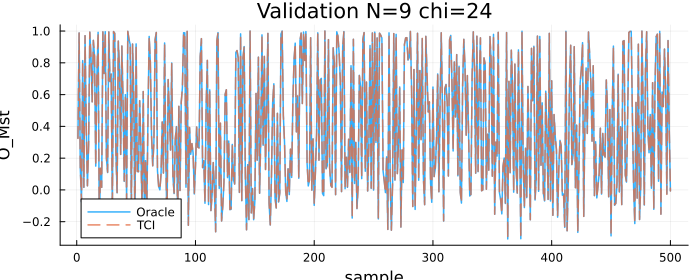

Processed -> results/processed/validation_N9_K3_chi24_20260611_124951.jls


In [8]:
phis    = [J -> J[k] for k in 1:4]
cores_C = ttF_to_ttC(cores_F, ωss; auxs=a_vec_list)
t_basis = make_basis_vectors(ωss, phis)

println("TT(C) shapes: ", [size(G) for G in cores_C])

relF = relerr_grid_2norm(f_idx, dims, cores_F; nsamples=2000, seed=RNG_SEED)
@printf("Grid rel-err (MC):     %.4f%%\n", relF*100)

rng_val  = MersenneTwister(RNG_SEED+1)
Js_val   = [2.0 .* rand(rng_val, 4) .- 1.0 for _ in 1:M_VAL]
y_true_v = [fq(J) for J in Js_val]
y_hat_v  = [eval_from_ttC(cores_C, t_basis, J) for J in Js_val]
ε_rel_val= sqrt(sum((y_true_v.-y_hat_v).^2)) / max(sqrt(sum(y_true_v.^2)), eps())
@printf("Random-point rel-err:  %.4f%%\n", ε_rel_val*100)

p_val = plot(1:M_VAL, y_true_v; lw=1.5, label="Oracle", alpha=0.8,
             xlabel="sample", ylabel="O_Mst",
             title="Validation N=$N_SINGLE chi=$CHI_MAX", size=(700,280))
plot!(p_val, 1:M_VAL, y_hat_v; lw=1.5, ls=:dash, label="TCI", alpha=0.8)
display(p_val)
savefig(p_val, joinpath(DIR_FIGURES, "validation_$(raw_tag)_$(RUN_ID).svg"))

proc_val_path = joinpath(DIR_PROCESSED, "validation_$(raw_tag)_$(RUN_ID).jls")
serialize(proc_val_path, Dict("N"=>N_SINGLE,"K"=>N_STEPS,"chi"=>CHI_MAX,
    "relF"=>relF,"eps_rel_val"=>ε_rel_val,"n_calls"=>ctr.n,
    "bonds"=>TCI.linkdims(tci)))
println("Processed -> $proc_val_path")


## 6. Figure 10(b) — True vs Approximated Heatmaps

Reproduce Figure 10(b) of the manuscript.  Fix J₁=J₂, J₄=−1;
sweep (J₁, J₃)∈[−1,1]².  Run TCI for each χ∈CHI_SCAN.

In [9]:
J1_vals = range(-1.0, 1.0; length=GRID_SIZE)
J3_vals = range(-1.0, 1.0; length=GRID_SIZE)

println("True grid ($GRID_SIZE x $GRID_SIZE)...")
t_grid = @elapsed begin
    y_true_grid = [fq([J1, J1, J3, J4_FIG]) for J1 in J1_vals, J3 in J3_vals]
end
@printf("  done %.1fs\n", t_grid)

serialize(joinpath(DIR_PROCESSED,
    "heatmap_true_N$(N_SINGLE)_K$(N_STEPS)_$(RUN_ID).jls"),
    Dict("J1"=>collect(J1_vals),"J3"=>collect(J3_vals),
         "y_true"=>y_true_grid,"J4"=>J4_FIG,"N"=>N_SINGLE))

heatmaps_approx = Dict{Int,Matrix{Float64}}()
tci_metrics     = Dict{Int,NamedTuple}()

for χ in CHI_SCAN
    println("--- chi=$χ ---")
    ctr_χ   = CounterWithLog(; verbose=false)
    fcach_χ = counted_unique_with_log(f_idx, ctr_χ)
    t_χ = @elapsed begin
        tci_χ, _, _ = TCI.crossinterpolate2(Float64, fcach_χ, dims;
            tolerance=TCI_TOL, maxbonddim=χ)
    end
    cF_χ = TCI.sitetensors(TCI.TensorTrain(tci_χ))
    cC_χ = ttF_to_ttC(cF_χ, ωss; auxs=a_vec_list)
    @printf("  calls=%d  t=%.1fs  bonds=%s\n",
            ctr_χ.n, t_χ, string(TCI.linkdims(tci_χ)))

    y_hat_grid = [eval_from_ttC(cC_χ, t_basis, [J1,J1,J3,J4_FIG])
                  for J1 in J1_vals, J3 in J3_vals]
    heatmaps_approx[χ] = y_hat_grid
    rmse_χ = sqrt(mean((y_true_grid .- y_hat_grid).^2))
    @printf("  RMSE=%.5f\n", rmse_χ)

    tci_metrics[χ] = (n_calls=ctr_χ.n, time_s=t_χ, rmse=rmse_χ,
                       bonds=TCI.linkdims(tci_χ))
    serialize(joinpath(DIR_RAW, "heatmap_chi$(χ)_N$(N_SINGLE)_$(RUN_ID).jls"),
        Dict("chi"=>χ,"y_hat"=>y_hat_grid,"n_calls"=>ctr_χ.n,"rmse"=>rmse_χ))
end
println("All chi runs done.")


True grid (200 x 200)...
  done 10.1s
--- chi=3 ---
  calls=832018  t=216.7s  bonds=[3, 3, 3]
  RMSE=0.30767
--- chi=6 ---
  calls=1713965  t=471.1s  bonds=[6, 6, 6]
  RMSE=0.14805
--- chi=9 ---
  calls=3145920  t=878.0s  bonds=[9, 9, 9]
  RMSE=0.15628
--- chi=12 ---
  calls=4862547  t=1394.5s  bonds=[12, 12, 9]
  RMSE=0.03137
All chi runs done.


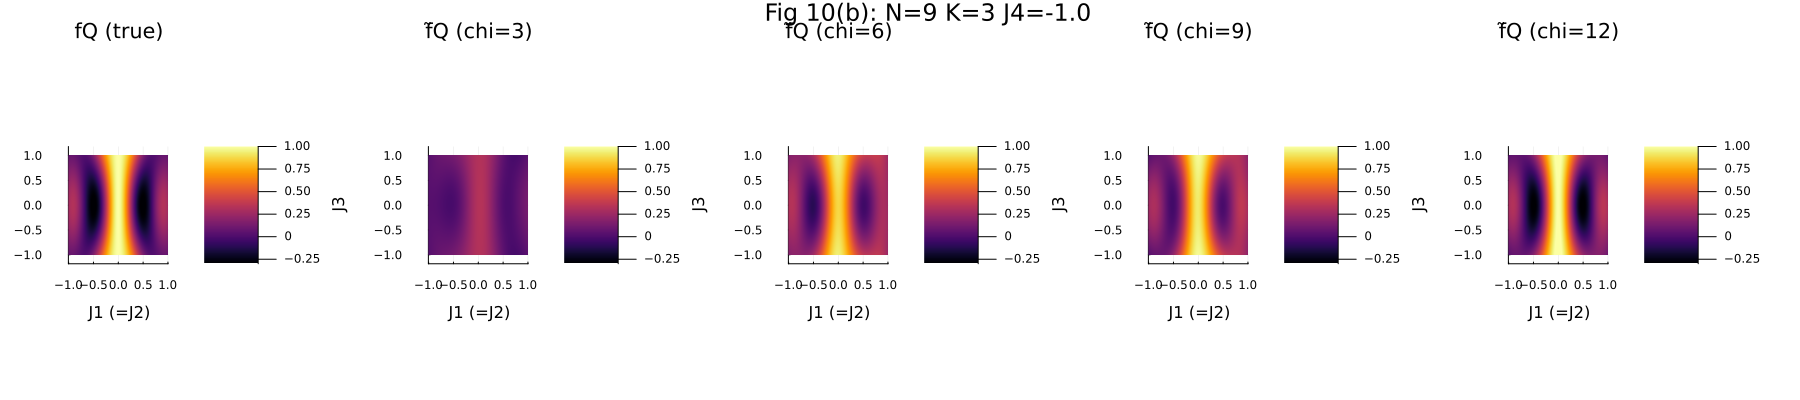

Saved -> figures/fig10b_N9_K3_20260611_124951.svg


In [10]:
clims = (-0.3, 1.0)
cmap  = :inferno

p_true = heatmap(collect(J1_vals), collect(J3_vals), y_true_grid';
    xlabel="J1 (=J2)", ylabel="J3", title="fQ (true)",
    clims=clims, color=cmap, aspect_ratio=1)

panels = [p_true]
for χ in sort(collect(keys(heatmaps_approx)))
    p_χ = heatmap(collect(J1_vals), collect(J3_vals), heatmaps_approx[χ]';
        xlabel="J1 (=J2)", ylabel="J3", title="f̃Q (chi=$χ)",
        clims=clims, color=cmap, aspect_ratio=1)
    push!(panels, p_χ)
end

fig10b = plot(panels...; layout=(1, length(panels)),
              size=(360*length(panels), 400),
              plot_title="Fig 10(b): N=$N_SINGLE K=$N_STEPS J4=$(J4_FIG)")
display(fig10b)

fig10b_path = joinpath(DIR_FIGURES, "fig10b_N$(N_SINGLE)_K$(N_STEPS)_$(RUN_ID).svg")
savefig(fig10b, fig10b_path)
println("Saved -> $fig10b_path")


## 7. Additional Figure: χ Convergence

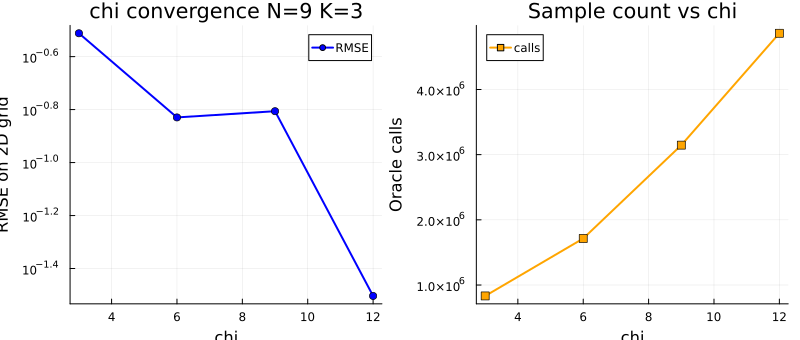

chi  RMSE           Oracle calls
3    3.0767e-01     832018      
6    1.4805e-01     1713965     
9    1.5628e-01     3145920     
12   3.1368e-02     4862547     


In [11]:
chis    = sort(collect(keys(tci_metrics)))
rmses   = [tci_metrics[χ].rmse    for χ in chis]
ncalls  = [tci_metrics[χ].n_calls for χ in chis]

p_chi_e = plot(chis, rmses; marker=:circle, lw=2, yscale=:log10, color=:blue,
    xlabel="chi", ylabel="RMSE on 2D grid",
    title="chi convergence N=$N_SINGLE K=$N_STEPS", label="RMSE")
p_chi_n = plot(chis, ncalls; marker=:square, lw=2, color=:orange,
    xlabel="chi", ylabel="Oracle calls", title="Sample count vs chi", label="calls")
fig_chi = plot(p_chi_e, p_chi_n; layout=(1,2), size=(800,340))
display(fig_chi)
savefig(fig_chi, joinpath(DIR_FIGURES, "chi_convergence_N$(N_SINGLE)_$(RUN_ID).svg"))

println("chi  RMSE           Oracle calls")
for (χ, r, n) in zip(chis, rmses, ncalls)
    @printf("%-4d %-14.4e %-12d\n", χ, r, n)
end
serialize(joinpath(DIR_PROCESSED,"chi_conv_N$(N_SINGLE)_$(RUN_ID).jls"),
    Dict("chis"=>chis,"rmses"=>rmses,"ncalls"=>ncalls))


## 8. Table I Reproduction

Loop over `N_LIST` with χ=24 (quick mode: χ=`CHI_MAX`).

**Expected (full mode, χ=24):**

| N | ε_rel | Sample # |
|---|-------|----------|
| 9 | 0.0033 | 6.785×10⁶ |
| 10 | 0.0021 | 5.478×10⁶ |
| 11 | 0.0044 | 1.286×10⁷ |
| 12 | 0.0025 | 8.828×10⁶ |

In [ ]:
chi_table = QUICK_MODE ? CHI_MAX : 24
println("Table I: N_LIST=$N_LIST  chi=$chi_table\n")

table_results = Dict{Int,NamedTuple}()



for Nb in N_LIST
    println("N = $Nb")
    dt_b   = T_EVOLVE / N_STEPS
    ωss_b  = vcat(
        [(2*dt_b).* collect(1:N_STEPS*(Nb-1)) for _ in 1:3],
        [(2*dt_b).* collect(1:N_STEPS*Nb)])
    dims_b   = [2*length(ωss_b[k])+1 for k in 1:4]
    Ms_b  = α .* dims_b   # M^(k) = α d_k
    rng_b    = MersenneTwister(RNG_SEED)
    gammas_b = gamma_vals(ωss_b)
    avecs_b  = [2π/gammas_b[k] .* rand(rng_b, Ms_b[k]) for k in 1:4]

    fq_b    = make_heisenberg_oracle_auto(Nb; n_steps=N_STEPS, t=T_EVOLVE,
                  maxdim=MPS_MAXDIM, cutoff=MPS_CUTOFF, crossover=YAO_CUTOVER)
    fidx_b  = id -> fq_b([avecs_b[p][id[p]] for p in 1:4])
    ctr_b   = CounterWithLog(; verbose=false)
    fcach_b = counted_unique_with_log(fidx_b, ctr_b)

    t_b = @elapsed begin
        tci_b, _, _ = TCI.crossinterpolate2(Float64, fcach_b, Ms_b;
            tolerance=TCI_TOL, maxbonddim=chi_table)
    end
    cF_b   = TCI.sitetensors(TCI.TensorTrain(tci_b))
    cC_b   = ttF_to_ttC(cF_b, ωss_b; auxs=avecs_b)
    tbas_b = make_basis_vectors(ωss_b, [J -> J[k] for k in 1:4])

    rng_vb = MersenneTwister(RNG_SEED+100+Nb)
    Js_vb  = [2.0 .* rand(rng_vb, 4) .- 1.0 for _ in 1:M_VAL]
    y_tb   = [fq_b(J) for J in Js_vb]
    y_hb   = [eval_from_ttC(cC_b, tbas_b, J) for J in Js_vb]
    ε_b    = sqrt(sum((y_tb.-y_hb).^2)) / max(sqrt(sum(y_tb.^2)), eps())

    table_results[Nb] = (N=Nb, chi=chi_table, eps_rel=ε_b,
                          n_calls=ctr_b.n, time_s=t_b, bonds=TCI.linkdims(tci_b))
    @printf("  eps_rel=%.4f  calls=%d  time=%.1fs\n", ε_b, ctr_b.n, t_b)

    serialize(joinpath(DIR_RAW,
        "table1_N$(Nb)_chi$(chi_table)_$(RUN_ID).jls"),
        Dict("N"=>Nb,"chi"=>chi_table,"eps_rel"=>ε_b,"n_calls"=>ctr_b.n))
end

println("\n=== Table I (chi=$chi_table) ===")
@printf("%-4s  %-8s  %-14s  %-10s\n","N","eps_rel","Sample #","Time (s)")
println("─"^42)
for Nb in N_LIST
    r = table_results[Nb]
    @printf("%-4d  %-8.4f  %-14d  %-10.1f\n", Nb, r.eps_rel, r.n_calls, r.time_s)
end
serialize(joinpath(DIR_PROCESSED,"table1_chi$(chi_table)_$(RUN_ID).jls"),table_results)
println("Saved -> results/processed/table1_chi$(chi_table)_$(RUN_ID).jls")

Table I: N_LIST=[9, 10, 11, 12, 13, 14, 15, 16]  chi=24

N = 9


[ Info: Hybrid oracle → Yao  (N=9 ≤ crossover=17, backend: statevector)


  eps_rel=0.0025  calls=6991295  time=2061.6s
N = 10
  eps_rel=0.0017  calls=7371628  time=2912.3s
N = 11

[ Info: Hybrid oracle → Yao  (N=10 ≤ crossover=17, backend: statevector)



  eps_rel=0.0027  calls=14866562  time=9420.2s
N = 12

[ Info: Hybrid oracle → Yao  (N=11 ≤ crossover=17, backend: statevector)


... (4 outputs left out)


  eps_rel=0.0020  calls=17560571  time=65172.8s
N = 15

[ Info: Hybrid oracle → Yao  (N=14 ≤ crossover=17, backend: statevector)



  eps_rel=0.0037  calls=25962131  time=197975.1s
N = 16

[ Info: Hybrid oracle → Yao  (N=15 ≤ crossover=17, backend: statevector)


In [4]:
# ════════════════════════════════════════════════════════════════════════
#  RESUME Table I — compute ONLY the missing N (N=16), reuse cached N=9–15
# ════════════════════════════════════════════════════════════════════════
#
#  HOW TO USE
#  ----------
#  Paste this into a NEW code cell directly below "## 8. Table I Reproduction".
#  Do NOT re-run the original Table I cell (it would wipe table_results and
#  recompute N=9–15 from scratch).
#
#  ▶ CONFIRMED SITUATION (2026-06-15): the kernel that ran N=9–15 is dead; the
#    current IJulia kernels are fresh, so `table_results` is NOT in memory.
#    This cell will rebuild N=9–15 from the on-disk .jls files, then run N=16.
#
#  BEFORE running this cell, run ONLY these two cells (top to bottom):
#     1) the top config cell (the big ╔═══════ banner block) — defines the
#        constants α, N_LIST, MPS_CUTOFF, YAO_CUTOVER, TCI_TOL, M_VAL, ... .
#     2) the "## 1. Setup" code cell — `include(...)` + `using .Modules`, which
#        defines make_heisenberg_oracle_auto, ttF_to_ttC, make_basis_vectors,
#        eval_from_ttC, gamma_vals, CounterWithLog, counted_unique_with_log,
#        and `import TensorCrossInterpolation as TCI`.
#     Sections 2–8 are NOT needed.
#
#  ⚠ Do NOT use "Run All Above" on this cell — that would re-execute the
#    original Table I cell and recompute N=9–15 from scratch (days of compute).
#
#  Recovered from disk: eps_rel & n_calls for N=9–15 (full fidelity).
#  Lost: time_s & bonds for N=9–15 (the raw .jls don't store them) → set to
#  NaN / empty. Those timings were sleep-inflated anyway; the on-screen output
#  still shows them if you ever want to transcribe them by hand.
#
#  ⚠ RUN_ID: the interrupted run is "20260611_124951". This is hard-pinned in
#  `rid` below so the patch always targets your existing files regardless of
#  whether cell 4 has been re-run.
# ════════════════════════════════════════════════════════════════════════

rid       = "20260611_124951"          # interrupted run's ID — matches results/raw/table1_N*_chi24_*.jls
chi_table = QUICK_MODE ? CHI_MAX : 24

# ── 1) Ensure table_results exists; backfill cached N from disk if needed ──
if !@isdefined(table_results)
    table_results = Dict{Int,NamedTuple}()
end
for Nb in N_LIST
    haskey(table_results, Nb) && continue          # keep full in-memory entry if present
    f = joinpath(DIR_RAW, "table1_N$(Nb)_chi$(chi_table)_$(rid).jls")
    if isfile(f)
        d = deserialize(f)
        table_results[Nb] = (N=d["N"], chi=d["chi"], eps_rel=d["eps_rel"],
                             n_calls=d["n_calls"], time_s=NaN, bonds=Int[])
        @info "recovered cached N=$Nb from disk (time_s/bonds unavailable)"
    end
end

missing_N = [Nb for Nb in N_LIST if !haskey(table_results, Nb)]
println("Resuming Table I (chi=$chi_table) — N still missing: $missing_N\n")

# ── 2) Compute ONLY the missing N (identical body to the original loop) ──
for Nb in missing_N
    println("N = $Nb")
    dt_b   = T_EVOLVE / N_STEPS
    ωss_b  = vcat(
        [(2*dt_b).* collect(1:N_STEPS*(Nb-1)) for _ in 1:3],
        [(2*dt_b).* collect(1:N_STEPS*Nb)])
    dims_b   = [2*length(ωss_b[k])+1 for k in 1:4]
    Ms_b  = α .* dims_b   # M^(k) = α d_k
    rng_b    = MersenneTwister(RNG_SEED)
    gammas_b = gamma_vals(ωss_b)
    avecs_b  = [2π/gammas_b[k] .* rand(rng_b, Ms_b[k]) for k in 1:4]

    fq_b    = make_heisenberg_oracle_auto(Nb; n_steps=N_STEPS, t=T_EVOLVE,
                  maxdim=MPS_MAXDIM, cutoff=MPS_CUTOFF, crossover=YAO_CUTOVER)
    fidx_b  = id -> fq_b([avecs_b[p][id[p]] for p in 1:4])
    ctr_b   = CounterWithLog(; verbose=false)
    fcach_b = counted_unique_with_log(fidx_b, ctr_b)

    t_b = @elapsed begin
        tci_b, _, _ = TCI.crossinterpolate2(Float64, fcach_b, Ms_b;
            tolerance=TCI_TOL, maxbonddim=chi_table)
    end
    cF_b   = TCI.sitetensors(TCI.TensorTrain(tci_b))
    cC_b   = ttF_to_ttC(cF_b, ωss_b; auxs=avecs_b)
    tbas_b = make_basis_vectors(ωss_b, [J -> J[k] for k in 1:4])

    rng_vb = MersenneTwister(RNG_SEED+100+Nb)
    Js_vb  = [2.0 .* rand(rng_vb, 4) .- 1.0 for _ in 1:M_VAL]
    y_tb   = [fq_b(J) for J in Js_vb]
    y_hb   = [eval_from_ttC(cC_b, tbas_b, J) for J in Js_vb]
    ε_b    = sqrt(sum((y_tb.-y_hb).^2)) / max(sqrt(sum(y_tb.^2)), eps())

    table_results[Nb] = (N=Nb, chi=chi_table, eps_rel=ε_b,
                          n_calls=ctr_b.n, time_s=t_b, bonds=TCI.linkdims(tci_b))
    @printf("  eps_rel=%.4f  calls=%d  time=%.1fs\n", ε_b, ctr_b.n, t_b)

    serialize(joinpath(DIR_RAW,
        "table1_N$(Nb)_chi$(chi_table)_$(rid).jls"),
        Dict("N"=>Nb,"chi"=>chi_table,"eps_rel"=>ε_b,"n_calls"=>ctr_b.n))
end

# ── 3) Final summary table + processed file (same format as original cell) ──
println("\n=== Table I (chi=$chi_table) ===")
@printf("%-4s  %-8s  %-14s  %-10s\n","N","eps_rel","Sample #","Time (s)")
println("─"^42)
for Nb in N_LIST
    r = table_results[Nb]
    @printf("%-4d  %-8.4f  %-14d  %-10.1f\n", Nb, r.eps_rel, r.n_calls, r.time_s)
end
serialize(joinpath(DIR_PROCESSED,"table1_chi$(chi_table)_$(rid).jls"), table_results)
println("Saved -> results/processed/table1_chi$(chi_table)_$(rid).jls")


[ Info: recovered cached N=9 from disk (time_s/bonds unavailable)
[ Info: recovered cached N=10 from disk (time_s/bonds unavailable)


Resuming Table I (chi=24) — N still missing: [16]

N = 16


[ Info: recovered cached N=11 from disk (time_s/bonds unavailable)
[ Info: recovered cached N=12 from disk (time_s/bonds unavailable)
[ Info: recovered cached N=13 from disk (time_s/bonds unavailable)
[ Info: recovered cached N=14 from disk (time_s/bonds unavailable)
[ Info: recovered cached N=15 from disk (time_s/bonds unavailable)
[ Info: Hybrid oracle → Yao  (N=16 ≤ crossover=17, backend: statevector)


  eps_rel=0.0020  calls=19818687  time=305052.2s

=== Table I (chi=24) ===
N     eps_rel   Sample #        Time (s)  
──────────────────────────────────────────
9     0.0025    6991295         NaN       
10    0.0017    7371628         NaN       
11    0.0027    14866562        NaN       
12    0.0039    9958224         NaN       
13    0.0032    23000948        NaN       
14    0.0020    17560571        NaN       
15    0.0037    25962131        NaN       
16    0.0020    19818687        305052.2  
Saved -> results/processed/table1_chi24_20260611_124951.jls


## 9. Additional Figure: ε_rel and Sample Count vs N

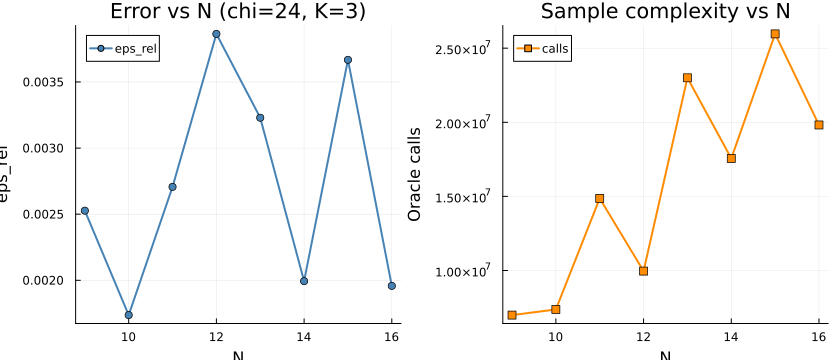

Saved -> figures/scaling_N_chi24_20260611_124951.svg


In [7]:
RUN_ID = "20260611_124951"   # pin to the existing run; matches rid and all on-disk files

Ns_p    = sort(collect(keys(table_results)))
eps_p   = [table_results[Nb].eps_rel  for Nb in Ns_p]
ncall_p = [table_results[Nb].n_calls  for Nb in Ns_p]

p_eN = plot(Ns_p, eps_p; marker=:circle, lw=2, color=:steelblue,
    xlabel="N", ylabel="eps_rel",
    title="Error vs N (chi=$chi_table, K=$N_STEPS)", label="eps_rel")
p_nN = plot(Ns_p, ncall_p; marker=:square, lw=2, color=:darkorange,
    xlabel="N", ylabel="Oracle calls",
    title="Sample complexity vs N", label="calls")

fig_sN = plot(p_eN, p_nN; layout=(1,2), size=(840,360))
display(fig_sN)
savefig(fig_sN, joinpath(DIR_FIGURES, "scaling_N_chi$(chi_table)_$(RUN_ID).svg"))
serialize(joinpath(DIR_PROCESSED,"scaling_N_chi$(chi_table)_$(RUN_ID).jls"),
    Dict("Ns"=>Ns_p,"eps"=>eps_p,"ncalls"=>ncall_p))
println("Saved -> figures/scaling_N_chi$(chi_table)_$(RUN_ID).svg")


## Figure 10(c) — Scalability and Validation

**Left**: Relative error $\hat{\varepsilon}_{\mathrm{rel}}$ and oracle sample count versus chain length $N$ ($\chi=24$, $K=3$).
**Right**: 100 random-point validation for the largest $N$ case, comparing oracle $f_Q$ to the FTCI approximation $\tilde{f}_Q$.

[ Info: Hybrid oracle → Yao  (N=16 ≤ crossover=17, backend: statevector)


Running TCI for N=16 (largest)...
  TCI done: calls=17881985  bonds=[24, 24, 5]  time=278086.7s
  N=16: eps_rel=0.0015  (100 validation points)


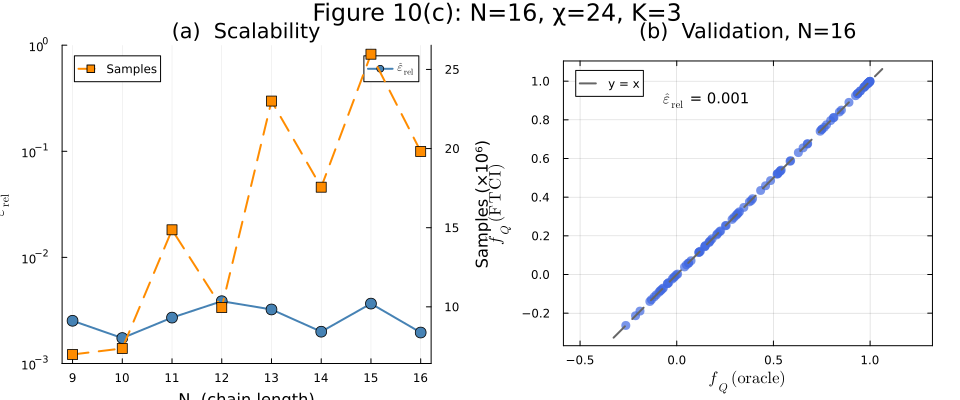

LoadError: UndefVarError: `RUN_ID` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [6]:
# ── Figure 10(c): Combined scalability + validation ──────────────────────────
Ns_fig    = sort(collect(keys(table_results)))
eps_fig   = [table_results[Nb].eps_rel  for Nb in Ns_fig]
ncall_fig = [table_results[Nb].n_calls  for Nb in Ns_fig]

# --- Left panel (a): eps_rel vs N ---
p_left = plot(Ns_fig, eps_fig;
    marker=:circle, ms=6, lw=2, color=:steelblue,
    xlabel="N  (chain length)", ylabel=L"\hat{\varepsilon}_{\mathrm{rel}}",
    title="(a)  Scalability",
    legend=:topright, label=L"\hat{\varepsilon}_{\mathrm{rel}}",
    yscale=:log10, ylims=(1e-3, 1.0),
    xticks=Ns_fig, grid=true, framestyle=:box)

# Twin axis: sample count (on same panel as secondary y)
p_left_twin = twinx(p_left)
plot!(p_left_twin, Ns_fig, ncall_fig ./ 1e6;
    marker=:square, ms=5, lw=2, color=:darkorange, ls=:dash,
    ylabel="Samples (×10⁶)", label="Samples",
    legend=:topleft)

# --- Right panel (b): 100 random-point validation for largest N ---
N_max     = maximum(Ns_fig)
dt_max    = T_EVOLVE / N_STEPS
ωss_max   = vcat(
    [(2*dt_max) .* collect(1:N_STEPS*(N_max-1)) for _ in 1:3],
    [(2*dt_max) .* collect(1:N_STEPS*N_max)])
dims_max  = [2*length(ωss_max[k])+1 for k in 1:4]
Ms_max  = α .* dims_max   # M^(k) = α d_k
rng_max   = MersenneTwister(RNG_SEED)
gammas_max= gamma_vals(ωss_max)
avecs_max = [2π/gammas_max[k] .* rand(rng_max, Ms_max[k]) for k in 1:4]

fq_max    = make_heisenberg_oracle_auto(N_max; n_steps=N_STEPS, t=T_EVOLVE,
                maxdim=MPS_MAXDIM, cutoff=MPS_CUTOFF, crossover=YAO_CUTOVER)
fidx_max  = id -> fq_max([avecs_max[p][id[p]] for p in 1:4])
ctr_max   = CounterWithLog(; verbose=false)
fcach_max = counted_unique_with_log(fidx_max, ctr_max)

println("Running TCI for N=$N_max (largest)...")
t_max = @elapsed begin
    tci_max, _, _ = TCI.crossinterpolate2(Float64, fcach_max, Ms_max;
        tolerance=TCI_TOL, maxbonddim=CHI_MAX)
end
cF_max  = TCI.sitetensors(TCI.TensorTrain(tci_max))
cC_max  = ttF_to_ttC(cF_max, ωss_max; auxs=avecs_max)
tbas_max= make_basis_vectors(ωss_max, [J -> J[k] for k in 1:4])

@printf("  TCI done: calls=%d  bonds=%s  time=%.1fs\n",
        ctr_max.n, string(TCI.linkdims(tci_max)), t_max)

# 100 random validation points
N_val_pts = 100
rng_v100  = MersenneTwister(RNG_SEED + 7777)
Js_v100   = [2.0 .* rand(rng_v100, 4) .- 1.0 for _ in 1:N_val_pts]
y_true100 = [fq_max(J) for J in Js_v100]
y_hat100  = [eval_from_ttC(cC_max, tbas_max, J) for J in Js_v100]
ε_100     = sqrt(sum((y_true100 .- y_hat100).^2)) / max(sqrt(sum(y_true100.^2)), eps())
@printf("  N=%d: eps_rel=%.4f  (%d validation points)\n", N_max, ε_100, N_val_pts)

p_right = scatter(y_true100, y_hat100;
    ms=5, alpha=0.7, color=:royalblue, markerstrokewidth=0,
    xlabel=L"f_Q \; \mathrm{(oracle)}", ylabel=L"\tilde{f}_Q \; \mathrm{(FTCI)}",
    title="(b)  Validation, N=$N_max",
    label="", aspect_ratio=1, grid=true, framestyle=:box)
lo, hi = extrema(vcat(y_true100, y_hat100))
pad = 0.05 * (hi - lo)
plot!(p_right, [lo-pad, hi+pad], [lo-pad, hi+pad];
    lw=2, ls=:dash, color=:gray40, label="y = x")
annotate!(p_right, lo + 0.15*(hi-lo), hi - 0.08*(hi-lo),
    text(L"\hat{\varepsilon}_{\mathrm{rel}}" * @sprintf(" = %.3f", ε_100),
         :left, 10, :black))

fig10c = plot(p_left, p_right; layout=(1,2), size=(960, 400),
              plot_title="Figure 10(c): N=$N_max, χ=$CHI_MAX, K=$N_STEPS",
              margin=5Plots.mm)
display(fig10c)

fig10c_path = joinpath(DIR_FIGURES, "fig10c_Nmax$(N_max)_chi$(CHI_MAX)_$(RUN_ID).svg")
savefig(fig10c, fig10c_path)
println("Saved → $fig10c_path")

serialize(joinpath(DIR_PROCESSED, "fig10c_data_$(RUN_ID).jls"),
    Dict("Ns"=>Ns_fig, "eps"=>eps_fig, "ncalls"=>ncall_fig,
         "N_max"=>N_max, "eps_100"=>ε_100,
         "y_true100"=>y_true100, "y_hat100"=>y_hat100))

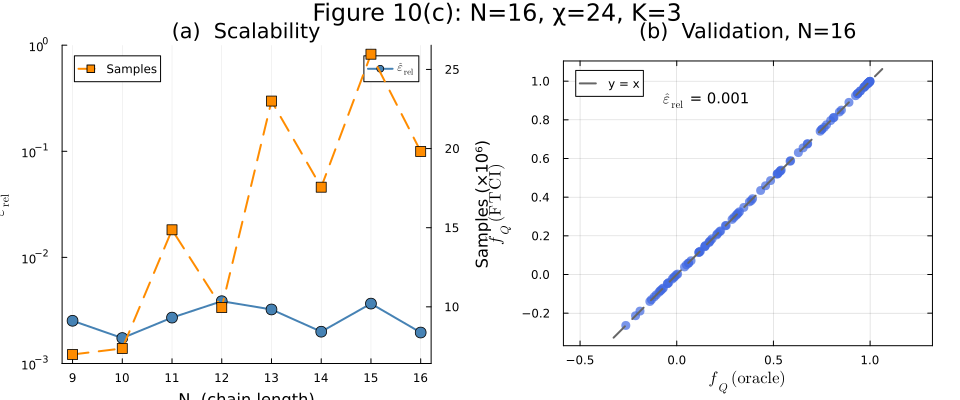

Saved → figures/fig10c_Nmax16_chi24_20260611_124951.svg


In [ ]:
#This block is for the only plot in the figure 12(c)
p_right = scatter(y_true100, y_hat100;
    ms=5, alpha=0.7, color=:royalblue, markerstrokewidth=0,
    xlabel=L"f_Q \; \mathrm{(oracle)}", ylabel=L"\tilde{f}_Q \; \mathrm{(FTCI)}",
    title="(b)  Validation, N=$N_max",
    label="", aspect_ratio=1, grid=true, framestyle=:box)
lo, hi = extrema(vcat(y_true100, y_hat100))
pad = 0.05 * (hi - lo)
plot!(p_right, [lo-pad, hi+pad], [lo-pad, hi+pad];
    lw=2, ls=:dash, color=:gray40, label="y = x")
annotate!(p_right, lo + 0.15*(hi-lo), hi - 0.08*(hi-lo),
    text(L"\hat{\varepsilon}_{\mathrm{rel}}" * @sprintf(" = %.3f", ε_100),
         :left, 10, :black))

fig10c = plot(p_left, p_right; layout=(1,2), size=(960, 400),
              plot_title="Figure 10(c): N=$N_max, χ=$CHI_MAX, K=$N_STEPS",
              margin=5Plots.mm)
display(fig10c)

fig10c_path = joinpath(DIR_FIGURES, "fig10c_Nmax$(N_max)_chi$(CHI_MAX)_$(RUN_ID).svg")
savefig(fig10c, fig10c_path)
println("Saved → $fig10c_path")

serialize(joinpath(DIR_PROCESSED, "fig10c_data_$(RUN_ID).jls"),
    Dict("Ns"=>Ns_fig, "eps"=>eps_fig, "ncalls"=>ncall_fig,
         "N_max"=>N_max, "eps_100"=>ε_100,
         "y_true100"=>y_true100, "y_hat100"=>y_hat100))

## 10. Additional Figure: Robustness Across Seeds

In [ ]:
Nb_rob  = first(N_LIST)
dt_rob  = T_EVOLVE / N_STEPS
ωss_rob = vcat(
    [(2*dt_rob).* collect(1:N_STEPS*(Nb_rob-1)) for _ in 1:3],
    [(2*dt_rob).* collect(1:N_STEPS*Nb_rob)])
dims_rob = [2*length(ωss_rob[k])+1 for k in 1:4]
Ms_rob  = α .* dims_rob   # M^(k) = α d_k
fq_rob   = make_heisenberg_oracle_auto(Nb_rob; n_steps=N_STEPS, t=T_EVOLVE,
               maxdim=MPS_MAXDIM, cutoff=MPS_CUTOFF, crossover=YAO_CUTOVER)

eps_seeds   = Float64[]
ncall_seeds = Int[]
println("Robustness: N=$Nb_rob  chi=$CHI_MAX  seeds=1:$N_SEEDS")

for seed in 1:N_SEEDS
    rng_s    = MersenneTwister(seed*1000)
    gammas_s = gamma_vals(ωss_rob)
    avecs_s  = [2π/gammas_s[k] .* rand(rng_s, Ms_rob[k]) for k in 1:4]
    fidx_s   = id -> fq_rob([avecs_s[p][id[p]] for p in 1:4])
    ctr_s    = CounterWithLog(; verbose=false)
    fcach_s  = counted_unique_with_log(fidx_s, ctr_s)
    tci_s,_,_ = TCI.crossinterpolate2(Float64, fcach_s, Ms_rob;
                    tolerance=TCI_TOL, maxbonddim=CHI_MAX)
    cF_s   = TCI.sitetensors(TCI.TensorTrain(tci_s))
    cC_s   = ttF_to_ttC(cF_s, ωss_rob; auxs=avecs_s)
    tbas_s = make_basis_vectors(ωss_rob, [J -> J[k] for k in 1:4])
    rng_vs = MersenneTwister(99999+seed)
    Js_vs  = [2.0 .* rand(rng_vs, 4) .- 1.0 for _ in 1:M_VAL]
    y_ts   = [fq_rob(J) for J in Js_vs]
    y_hs   = [eval_from_ttC(cC_s, tbas_s, J) for J in Js_vs]
    ε_s    = sqrt(sum((y_ts.-y_hs).^2)) / max(sqrt(sum(y_ts.^2)), eps())
    push!(eps_seeds, ε_s); push!(ncall_seeds, ctr_s.n)
    @printf("  seed=%d: eps_rel=%.4f  calls=%d\n", seed, ε_s, ctr_s.n)
end

@printf("eps_rel: mean=%.4f +/- %.4f\n", mean(eps_seeds), std(eps_seeds))
@printf("calls:   mean=%.0f +/- %.0f\n", mean(ncall_seeds), std(ncall_seeds))

p_rob = scatter(1:N_SEEDS, eps_seeds; marker=:circle, ms=7, color=:royalblue,
    xlabel="Seed", ylabel="eps_rel",
    title="Robustness N=$Nb_rob chi=$CHI_MAX", label="eps per seed")
hline!(p_rob, [mean(eps_seeds)]; ls=:dash, lw=2, color=:royalblue, label="mean")
display(p_rob)
savefig(p_rob, joinpath(DIR_FIGURES,
    "robustness_N$(Nb_rob)_chi$(CHI_MAX)_$(RUN_ID).svg"))
serialize(joinpath(DIR_PROCESSED,
    "robustness_N$(Nb_rob)_chi$(CHI_MAX)_$(RUN_ID).jls"),
    Dict("N"=>Nb_rob,"eps"=>eps_seeds,"ncalls"=>ncall_seeds))
println("Saved robustness results.")

## 11. Oracle Scaling Benchmark (optional, skipped in QUICK_MODE)

In [28]:
run_bench = !QUICK_MODE   # flip to true to force benchmark

if run_bench
    Ns_mps  = N_SCALE
    Ns_yao  = filter(n -> n <= 16, Ns_mps)
    J_bench = [1.0, 1.0, 0.5, -1.0]
    n_reps  = 3

    println("=== MPS ===")
    times_mps = Float64[]
    for Nb in Ns_mps
        fq_b = HeisenbergMPS.make_heisenberg_oracle(Nb; n_steps=4, t=1.0,
                    maxdim=MPS_MAXDIM, cutoff=MPS_CUTOFF)
        fq_b(J_bench)
        ts = [(@elapsed fq_b(J_bench)) for _ in 1:n_reps]
        push!(times_mps, median(ts))
        @printf("  N=%2d: %.4f s\n", Nb, median(ts))
    end

    println("=== Yao ===")
    times_yao = Float64[]
    for Nb in Ns_yao
        fq_b = HeisenbergYao.make_heisenberg_oracle_yao(Nb; n_steps=4, t=1.0)
        fq_b(J_bench)
        ts = [(@elapsed fq_b(J_bench)) for _ in 1:n_reps]
        push!(times_yao, median(ts))
        @printf("  N=%2d: %.4f s\n", Nb, median(ts))
    end

    ref_val  = times_yao[1]
    ref_N    = first(Ns_yao)
    Ns_ref   = collect(range(first(Ns_mps), last(Ns_mps); step=1))
    ref_line = ref_val .* (2.0 .^ (Ns_ref .- ref_N))

    p_b = plot(Ns_mps, times_mps; marker=:circle, lw=2, color=:steelblue,
        label="MPS (maxdim=$MPS_MAXDIM)", xlabel="N", ylabel="t/call (s)",
        title="Oracle scaling K=4 t=1", yscale=:log10, legend=:topleft)
    plot!(p_b, Ns_yao, times_yao; marker=:square, lw=2, color=:crimson, label="Yao")
    plot!(p_b, Ns_ref, ref_line; lw=1, ls=:dot, color=:gray, label="O(2^N)")
    vline!(p_b, [YAO_CUTOVER]; ls=:dash, lw=1, color=:black, label="cutover")
    display(p_b)
    savefig(p_b, joinpath(DIR_FIGURES, "oracle_scaling_$(RUN_ID).svg"))
    serialize(joinpath(DIR_PROCESSED, "oracle_bench_$(RUN_ID).jls"),
        Dict("Ns_mps"=>Ns_mps,"t_mps"=>times_mps,"Ns_yao"=>Ns_yao,"t_yao"=>times_yao))
    println("Saved oracle benchmark.")
else
    println("Benchmark skipped (QUICK_MODE=true). Set run_bench=true to force.")
end


=== MPS ===


UndefVarError: UndefVarError: `make_heisenberg_oracle` not defined in `Main`
Hint: It looks like two or more modules export different bindings with this name, resulting in ambiguity. Try explicitly importing it from a particular module, or qualifying the name with the module it should come from.

## 12. Sanity Check

In [ ]:
println("╔══════════════════════════════════════════════════════════════╗")
println("║                    SANITY CHECK SUMMARY                     ║")
println("╚══════════════════════════════════════════════════════════════╝")
@printf("Run ID  : %s\n", RUN_ID)
@printf("Mode    : %s\n", QUICK_MODE ? "QUICK" : "FULL")
@printf("N=%d K=%d chi_max=%d grid=%dx%d\n",N_SINGLE,N_STEPS,CHI_MAX,GRID_SIZE,GRID_SIZE)
println()

ok  = true
nok = 0
function chk(path, label)
    global ok, nok
    e = isfile(path) || isdir(path)
    println("  $(e ? "ok" : "MISSING")  $label")
    ok = ok && e; nok += e ? 1 : 0
end

println("Logs:")
chk(joinpath(DIR_LOGS, "config_$(RUN_ID).txt"), "config log")

println("Raw:")
chk(joinpath(DIR_RAW, "tci_$(raw_tag)_$(RUN_ID)"), "TCI dir N=$N_SINGLE chi=$CHI_MAX")
for Nb in N_LIST
    chk(joinpath(DIR_RAW,"table1_N$(Nb)_chi$(chi_table)_$(RUN_ID).jls"),"Table I N=$Nb")
end
for χ in CHI_SCAN
    chk(joinpath(DIR_RAW,"heatmap_chi$(χ)_N$(N_SINGLE)_$(RUN_ID).jls"),"heatmap chi=$χ")
end

println("Processed:")
chk(proc_val_path, "validation metrics")
chk(joinpath(DIR_PROCESSED,"heatmap_true_N$(N_SINGLE)_K$(N_STEPS)_$(RUN_ID).jls"),"true heatmap")
chk(joinpath(DIR_PROCESSED,"chi_conv_N$(N_SINGLE)_$(RUN_ID).jls"),     "chi convergence")
chk(joinpath(DIR_PROCESSED,"table1_chi$(chi_table)_$(RUN_ID).jls"),    "Table I processed")
chk(joinpath(DIR_PROCESSED,"scaling_N_chi$(chi_table)_$(RUN_ID).jls"), "N-scaling data")
chk(joinpath(DIR_PROCESSED,"robustness_N$(first(N_LIST))_chi$(CHI_MAX)_$(RUN_ID).jls"),
    "robustness data")

println("Figures:")
figs = filter(f -> contains(f, RUN_ID), readdir(DIR_FIGURES))
for f in sort(figs); println("  ok  figures/$f"); end
nok += length(figs)

println()
@printf("Key metrics (N=%d, chi=%d):\n", N_SINGLE, CHI_MAX)
@printf("  Oracle calls (main):  %d\n",    ctr.n)
@printf("  Grid rel-err:         %.4f%%\n", relF*100)
@printf("  Continuous eps_rel:   %.4f%%\n", ε_rel_val*100)
@printf("  TCI bond dims:        %s\n",    string(TCI.linkdims(tci)))
println()

if QUICK_MODE
    println("Expected ranges (QUICK_MODE N=4 K=2 chi=6):")
    println("  Oracle calls: ~100 - 3000")
    println("  Grid rel-err: < 0.01% (TCI exact on grid)")
    println("  eps_rel:      < 20%")
end
println()
ok ? println("ALL ARTIFACTS PRESENT — pipeline verified.") :
     println("WARNING: some artifacts missing (see MISSING above)")


╔══════════════════════════════════════════════════════════════╗
║                    SANITY CHECK SUMMARY                     ║
╚══════════════════════════════════════════════════════════════╝
Run ID  : 20260305_154012
Mode    : QUICK
N=4 K=2 chi_max=6 grid=20x20

Logs:
  ok  config log
Raw:
  ok  TCI dir N=4 chi=6
  ok  Table I N=4
  ok  heatmap chi=3
  ok  heatmap chi=6
Processed:
  ok  validation metrics
  ok  true heatmap
  ok  chi convergence
  ok  Table I processed
  ok  N-scaling data
  ok  robustness data
Figures:
  ok  figures/chi_convergence_N4_20260305_154012.pdf
  ok  figures/fig10b_N4_K2_20260305_154012.pdf
  ok  figures/robustness_N4_chi6_20260305_154012.pdf
  ok  figures/scaling_N_chi6_20260305_154012.pdf
  ok  figures/validation_N4_K2_chi6_20260305_154012.pdf

Key metrics (N=4, chi=6):
  Oracle calls (main):  12437
  Grid rel-err:         15.8973%
  Continuous eps_rel:   33.1816%
  TCI bond dims:        [6, 5, 2]

Expected ranges (QUICK_MODE N=4 K=2 chi=6):
  Oracle ca